# Career Exploration Engine: Phase 1 process notebook

**Goal of Phase 1.** From a participant's CV and PersonaMap personality report (plus a short interests
intake), produce a short, explainable **Top 10 list of career areas**, without asking anyone to rate
~100 options.

**This notebook is the record of what we did and why**, in the order we did it, including the first
attempt that failed its own quality check. Everything here is regenerated from the code in `src/careerx/`
(`python notebooks/build_notebook.py`), and the same engine drives the test app (`streamlit run app/streamlit_app.py`).

| Section | What it covers |
|---|---|
| 1 | What the principal consultant asked for (requirements checklist) |
| 2 | The inputs: participant documents and the two ISCO workbooks |
| 3 | The key design question: "why not map every person to every job?" |
| 4 | Building the Career Area Catalogue from ISCO |
| 5 | Building the participant profile |
| 6 | Scoring every area, and the selectivity gate |
| 7 | Dry run 1 failed: what we found and how we fixed it |
| 8 | Reading the result: evidence, false negatives, hidden passions |
| 9 | What actually drives the ranking (ablation and sensitivity) |
| 10 | Narrowing to a Top 10 with the participant's own reactions |
| 11 | Validation design for the internal testers |
| 12 | Outputs written to disk |
| 13 | Findings, limitations and next steps |

> **Status honesty.** One participant (Thilakshana R) has been run. No human validation has happened yet.
> Everything below is a *first dry run* to be validated by the testers, not a result.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from careerx import isco, catalogue, lexicon, profile as P, scoring, narrowing, feedback, report
from careerx import pipeline as PL

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("project root:", ROOT)

project root: C:\Users\lnipu\SANDBOX\Personality matching system


## 1. What the principal consultant asked for

Taken from the meeting transcript (`data/raw/Requirements.md`). The checklist below is what the rest of the
notebook is measured against.

| # | Requirement from the transcript | Where handled |
|---|---|---|
| R1 | Recommend **career areas, not designations** ("data analyst" the field, not "associate analyst" the title). | §4 catalogue |
| R2 | Use **ISCO** (international standard, also the base of O\*NET) as the basis, adaptable for Sri Lanka later. | §2, §4 |
| R3 | Roughly 100-200 areas. **Map each tester to all of them** in internal research, then ask for feedback. | §6, §11 |
| R4 | Do **not** show a person 100+ options ("a 500-page menu"). Show a short list: **two lists of 10**, highly and moderately suitable. | §10 |
| R5 | **Sanity check:** if someone matches 120 of 150 areas, the system is broken. | §6 selectivity gate |
| R6 | Testers rate **each line of a numbered list** for accuracy (1-5), with a **comment whenever it is not highly accurate**; target ~90% accuracy over about 3 refinement rounds. | §11 |
| R7 | The CV is not enough: ask about **passions and interests** (the "music not on my CV" case). | §5, §8 |
| R8 | Let the participant react to suggestions ("why did you pick this / not that"). | §10 |
| R9 | Both **personality and leadership** inputs feed the match. | §5: personality is used. The PersonaMap report's *leadership-style* section (Goleman styles) is in the PDF but **not yet used by the engine**; no separate leadership questionnaire output has been provided |
| R10 | Later (not Phase 1): study vs. professional path, apply through the platform, employers invited by email. | §13 |

**One requirement is deliberately interpreted:** the consultant wants *every* tester mapped to *all* areas.
We do exactly that (the machine scores all of them). What we avoid is asking a **human** to react to all of
them. §3 explains the distinction.

## 2. The inputs

Five files were provided: the CV, the PersonaMap report, the requirements transcript and two ISCO workbooks.

### 2.1 The participant: Thilakshana R

The text of both PDFs is parsed by `careerx.profile`. First, what the personality report says (the four
preference percentages are *parsed from the report text*, not typed in):

In [2]:
cv_text = P.extract_pdf_text(PL.SAMPLE_CV)
pm_text = P.extract_pdf_text(PL.SAMPLE_PM)
pm = P.parse_personamap(pm_text)
pd.DataFrame([
    ("Extroversion (E vs I)", pm["E"], "exactly balanced; report says no pattern underneath"),
    ("Intuition (N vs S)",    pm["N"], "moderate"),
    ("Feeling (F vs T)",      pm["F"], "slight; near-even"),
    ("Judging (J vs P)",      pm["J"], "moderate; the clearest preference"),
], columns=["dimension", "% of first pole", "report's reading"]).set_index("dimension")

,% of first pole,report's reading
dimension,,
Extroversion (E vs I),50.0,exactly balanced; report says no pattern underneath
Intuition (N vs S),70.0,moderate
Feeling (F vs T),55.0,slight; near-even
Judging (J vs P),65.0,moderate; the clearest preference


**What the two documents say, in my own summary** (so a reader does not need to open the PDFs):

* **CV:** BSc (Hons) IT specialising in Data Science (CGPA 3.5). Currently a Data Analytics intern at Sandbox
  (regression, dashboards, location intelligence, requirements gathering, QA, workforce/culture research),
  previously an AI/ML engineer intern. Projects: a bipolar-risk NLP system with an IEEE paper, an IoT climate
  system, a MERN web system for an Ayurvedic centre, an airline-satisfaction classifier.
* **PersonaMap (XNFJ, Idealist; ENFJ "Connection Builder" / INFJ "Visionweaver"):** plans very consistently
  but closes decisions slowly; reads how others see a situation; explains abstract material through analogy;
  warm but willing to say the difficult thing. Energy dimension is *genuinely balanced*, and the report
  explicitly refuses to invent a pattern there.

Two things in the report matter for the design: it states it measures **preferences, not ability**, and it is
marked **confidential, not for selection decisions**. The engine therefore only uses personality to *re-order*
areas for the participant's own exploration (§6), and gives a balanced dimension zero weight (§6.2).

### 2.2 ISCO-08 structure and definitions

ISCO-08 is a four-level tree. Every row carries a definition, typical tasks and example occupations.

In [3]:
s = isco.load_structure()
lv = s.groupby("level_name").size().reindex(["major", "sub_major", "minor", "unit"]).rename("groups")
display(lv.to_frame())
print("Example row (a unit group):")
r = s[(s.level == 4) & (s.code == "2120")].iloc[0]
print(r.code, "|", r.title)
print("  definition:", isco.clean_text(r.definition)[:230], "...")
print("  examples  :", isco.example_occupations(r.included)[:5])

,groups
level_name,
major,10
sub_major,43
minor,130
unit,436


Example row (a unit group):
2120 | Mathematicians, Actuaries and Statisticians
  definition: Mathematicians, actuaries and statisticians conduct research and improve or develop mathematical, actuarial and statistical concepts, theories and operational methods and techniques and advise on or engage in their practical appli ...
  examples  : ['Actuary', 'Demographer', 'Mathematician', 'Operations research analyst', 'Statistician']


**The "9 sectors" in the brief.** ISCO has 10 *major groups*; the 10th is Armed Forces, which we exclude, which
gives the 9. The 43 *sub-major* groups are the "sub groups". The finer 130 *minor groups* are the natural size
for a catalogue of "100-200 areas" (R3). We come back to why we do **not** simply drill major → sub-major in §3.

### 2.3 The "ISCO-08 / 88 Skills" workbook

This is **not** a skills taxonomy (we checked, because the name suggests one). It only maps each ISCO major
group to one of four *skill levels* (and ISCO-08 to ISCO-88 groups). That is still useful: it tells us the
**education/skill band** each group typically needs, which we use as a *readiness* factor.

In [4]:
sk = isco.load_skill_levels().drop_duplicates("major")[["major", "major_label", "skill_level", "skill_label"]]
sk

,major,major_label,skill_level,skill_label
0,1,Managers,3,Skill levels 3 and 4 (high)
4,2,Professionals,3,Skill levels 3 and 4 (high)
10,3,Technicians and Associate Professionals,3,Skill levels 3 and 4 (high)
15,4,Clerical Support Workers,2,Skill level 2 (medium)
19,5,Services And Sales Workers,2,Skill level 2 (medium)
23,6,"Skilled Agricultural, Forestry and Fishery Workers",2,Skill level 2 (medium)
26,7,Craft and Related Trades Workers,2,Skill level 2 (medium)
31,8,Plant and Machine Operators and Assemblers,2,Skill level 2 (medium)
34,9,Elementary Occupations,1,Skill level 1 (low)
40,0,Armed Forces Occupations,4,n.e.c


## 3. "Why not map every person to every job?"

The concern: with ~150 profiles, mapping a person to all of them is impractical. Two different things hide in
that sentence, and separating them is the whole design:

| | Mapping / scoring | Asking a human to rate |
|---|---|---|
| Cost | Milliseconds. A computer scores 100 areas as easily as 10. | ~100 judgements per person: fatigue, noise, random answers. |
| Needed? | **Yes**, the consultant wants the full map, and the quality gate (R5) is impossible without scoring everything. | **No**, only for a short list. |

So: **score everything, show narrow, rate in clusters.**

### 3.1 Why we do not drill "sector → sub-group → jobs"

The natural idea is to pick one of the 9 sectors, then a sub-group, then list jobs. The ISCO data itself
shows why that is unsafe. ISCO major groups are organised mainly by **kind and level of work** (managers,
professionals, technicians/associate professionals, clerks, ...), *not by field*: the same field is split
across several major groups.

In [5]:
mg = isco.minor_groups().set_index("code")
codes = ["212", "241", "242", "331", "251", "252", "351", "352", "263", "265", "343", "221", "222", "321", "322"]
fields = {"212": "statistics", "241": "finance", "331": "finance", "242": "organisation analysis",
          "251": "ICT", "252": "ICT", "351": "ICT", "352": "ICT", "263": "social / psychology",
          "265": "arts", "343": "arts", "221": "health", "222": "health", "321": "health", "322": "health"}
kind = {"1": "managers", "2": "professionals", "3": "technicians / associate professionals"}
tbl = pd.DataFrame({
    "title": [mg.loc[c, "title"] for c in codes],
    "field": [fields[c] for c in codes],
    "major group": [c[0] for c in codes],
    "kind of work": [kind[c[0]] for c in codes],
}, index=codes)
tbl.sort_values(["field", "major group"])

,title,field,major group,kind of work
251,Software and Applications Developers and Analysts,ICT,2,professionals
252,Database and Network Professionals,ICT,2,professionals
351,Information and Communications Technology Operations and User Support Techni...,ICT,3,technicians / associate professionals
352,Telecommunications and Broadcasting Technicians,ICT,3,technicians / associate professionals
265,Creative and Performing Artists,arts,2,professionals
343,"Artistic, Cultural and Culinary Associate Professionals",arts,3,technicians / associate professionals
241,Finance Professionals,finance,2,professionals
331,Financial and Mathematical Associate Professionals,finance,3,technicians / associate professionals
221,Medical Doctors,health,2,professionals
222,Nursing and Midwifery Professionals,health,2,professionals


Reading that table:

* **ICT** sits in major 2 (professionals) *and* major 3 (technicians); **health** in 2 and 3; **finance** in
  2 and 3; **arts** in 2 and 3. A drill-down by major group would treat "nurse" and "nursing associate" as
  different *sectors*.
* The consultant asked for **"area, not designation, not level"** (R1). So the catalogue must **merge across
  levels** (§4), and the funnel must not commit to a single branch early.
* The consultant himself has "6-7 areas" (arts, music, technology, analytics, entrepreneurship). A single
  sector path would delete most of them on step one, and one early wrong guess would be unrecoverable.

**Decision D1:** replace a hard funnel with a *soft* one, namely score all areas, keep the top ~20 (plus any
areas the participant says they are passionate about), and let the participant narrow from there.

## 4. Building the Career Area Catalogue

**Rules** (written in `src/careerx/catalogue.py`):

1. Base unit = ISCO **minor group**. Armed Forces (3 groups) are out of scope.
2. **Merge** groups that are the same field across levels (e.g. nursing professionals + nursing associate
   professionals).
3. **Rename** each area to a field noun ("Software & applications development"), not a designation.
4. Add a few **"lens" areas** carved out of unit groups that ISCO-08 (written in 2008) lumps together or
   predates: data science, AI/ML, UX, IoT, cybersecurity, psychology research, economics/policy, training &
   development, music. They overlap their parents *on purpose*, are flagged `kind = lens`, and carry a short,
   visible supplement text so the added vocabulary is auditable.
5. Each area keeps its ISCO codes, definition + task text, example roles, a **field cluster** and the
   **skill-band range** it spans.

In [6]:
cat = PL.get_catalogue()
cov = catalogue.coverage_report(cat)
print({k: v for k, v in cov.items()})
assert cov["missing"] == [] and cov["duplicates"] == []
print("\nEvery in-scope ISCO minor group is in exactly one merged area.")

{'isco_minor_total': 130, 'excluded_armed_forces': 3, 'in_scope': 127, 'assigned': 127, 'missing': [], 'unknown': [], 'duplicates': [], 'areas_isco': 85, 'areas_lens': 9, 'areas_total': 94}

Every in-scope ISCO minor group is in exactly one merged area.


In [7]:
display(cat.groupby("cluster").agg(areas=("name", "count"),
                                   isco_unit_groups=("n_isco_units", "sum")).sort_values("areas", ascending=False))
display(cat[cat.kind == "isco"].query("isco_minor.str.contains(',')")[["area_id", "name", "isco_minor"]].head(12))
display(cat[cat.kind == "lens"][["area_id", "name", "isco_units"]])

,areas,isco_unit_groups
cluster,,
"Production, Trades, Transport & Operations",19,127
"Business, Finance & Management",16,68
"Hospitality, Retail & Personal Services",13,61
"Education, Social & Public Service",12,45
"Health, Care & Wellbeing",10,38
Technology & Data,9,35
"Creative, Media & Culture",6,29
"Science, Engineering & Built Environment",6,36
"Agriculture, Forestry & Fisheries",3,26


,area_id,name,isco_minor
4,A005,Agricultural production & farm management,"131,611,612,613"
13,A014,"Life sciences, biology & laboratory science","213,314"
14,A015,Engineering & engineering technology,"214,311"
18,A019,Nursing & midwifery,"222,322"
19,A020,Traditional & complementary medicine,"223,323"
21,A022,Veterinary science & animal health,"225,324"
30,A031,Primary & early-childhood teaching and child care,"234,531"
32,A033,"Finance, accounting & financial analysis","241,331"
34,A035,"Sales, marketing & public relations","243,332"
36,A037,Administrative & executive support,"334,412"


,area_id,name,isco_units
85,A086,Data science & analytics,"2120,2511,2521,2421"
86,A087,AI & machine learning engineering,"2511,2512,2519,2120"
87,A088,"UX, product & digital design","2513,2166,2519,2511"
88,A089,"IoT, embedded & smart systems","2152,2153,2519,3511"
89,A090,Cybersecurity & information security,"2523,2529,2522"
90,A091,Psychology & behavioural research,"2634,2632,2635,2120"
91,A092,Economics & public policy analysis,"2631,2422,2120"
92,A093,"Training, learning & development","2424,2356,2351"
93,A094,Music performance & production,"2652,2654,3521"


**What this gives us:** 94 career areas (85 merged ISCO areas + 9 lens areas) grouped into **9 field
clusters**. The 9 clusters play the role the "9 sectors" were meant to: a human-sized way to browse, but
organised by *field* instead of skill level.

**Known weakness (D2):** ISCO describes jobs, not *modes* of work. "Entrepreneurship" is not an ISCO
area, so it enters only as an interest concept (§5), not as a catalogue row. Likewise Sri Lanka-specific
occupations need a later local adaptation (the consultant mentioned this in R2).

## 5. Building the participant profile

The profile builder (`careerx.profile`) turns documents into three things:

1. **Concept evidence from the CV.** A plain, editable *lexicon* (`careerx.lexicon`) lists ~35 concepts
   (statistics, machine learning, teaching, finance, music...). Each has CV trigger phrases and an ISCO-style
   vocabulary. A concept's strength is `raw / (raw + 4)` where `raw = distinct triggers + 0.3 × extra mentions`,
   and the matched phrases are kept as **cited evidence**.
2. **Personality preferences** parsed from the PersonaMap text (§2.1).
3. **Education band and experience**, detected from the CV and **editable** in the app.
4. **Interests**, the new intake from R7. For Thilakshana none has been collected yet; the engine
   treats this as *unknown* and does **not** guess.

In [8]:
prof = PL.sample_profile()
print("education band:", prof.education_band, "|", prof.education_note)
print("years experience (work-experience section only):", prof.years_experience)
ev = pd.DataFrame([dict(concept=lexicon.CONCEPT_BY_ID[k].label, strength=v["strength"], n_mentions=v["n_hits"],
                        evidence=", ".join(v["hits"])) for k, v in prof.cv_concepts.items()]
                  ).sort_values("strength", ascending=False).reset_index(drop=True)
ev

education band: 3 | Tertiary / degree-level education found in CV
years experience (work-experience section only): 1.3


,concept,strength,n_mentions,evidence
0,Software development,0.778,21,"python, java, javascript, mern, react"
1,Databases & data engineering,0.748,21,"mysql, mongodb, oracle, sqlite, data warehous"
2,Data analytics & visualisation,0.735,16,"data analy, data mining, dashboard, visual analytics, power bi"
3,Machine learning & AI,0.695,14,"machine learning, ai, nlp, natural language, classification model"
4,"IoT, embedded & electronics",0.669,13,"iot, arduino, esp32, sensor, microcontroller"
5,Statistics & quantitative modelling,0.633,9,"statistic, regression, forecast, arima, data sampling"
6,"Market, customer & location insight",0.583,7,"market, location intelligence, spatial, growth opportunit, consumer"
7,Psychology & mental health,0.579,9,"bipolar, mental, emotion, behavior"
8,Systems & requirements analysis,0.570,6,"requirement, specification, system testing, quality assurance, data validation"
9,Organisation & workforce analysis,0.570,6,"workforce, organizational, culture, stakeholder, recommendation"


### 5.1 Two bugs the first look exposed (and the fixes)

Running the profile builder for the first time showed problems that were worth fixing *before* scoring:

* **Referees leaked in.** The CV's REFERENCES section lists "Assistant Lecturer" and "CEO / Founder". Those are
  the referees' jobs, not hers. Naively, that made *teaching* and *entrepreneurship* look like CV strengths.
* **Generic words.** "environment" (as in "Agile team environment") triggered agriculture/environment;
  "translating requirements" triggered translation/writing.
* **Saturation.** The first strength formula hit 1.0 for 14 concepts, so nothing was ranked within the CV.

Demonstration of the first one:

In [9]:
raw_hits = P.detect_concepts(cv_text)
clean_hits = P.detect_concepts(P.strip_references(cv_text))
leaked = sorted(set(raw_hits) - set(clean_hits))
print("concepts that only appear because of the REFERENCES section:", leaked)
for k in leaked:
    print(" ", k, "->", raw_hits[k]["hits"])

concepts that only appear because of the REFERENCES section: ['entrepreneurship', 'teaching']
  entrepreneurship -> ['founder']
  teaching -> ['lectur']


**Caution on over-fitting (D3).** These lexicon fixes were made after looking at *this one* CV. That is
normal for a first dry run, but it means Thilakshana's result is partly "tuned to her". The four other
testers are the real test of the lexicon, which is exactly what the consultant's validation rounds are for.

## 6. Scoring every area

### 6.1 The formula (final version)

```
score  =  100  ×  relevance  ×  work_style_modifier  ×  readiness

relevance            = 1 - (1 - cv) × (1 - interest_strength × interests)      # probabilistic OR
work_style_modifier  = (1 - influence) + influence × personality_fit           # re-orders, never creates
readiness            = 1.0 if education fits the area's ISCO skill band, else 0.55 / 0.30 / 0.25
                       (managerial areas are further scaled by years of experience)
```

* **cv**: for each concept in the CV, how strongly the area's own ISCO text talks about that concept
  (TF-IDF cosine between the concept vocabulary and the area text, per-concept normalised), weighted by the
  concept's strength on the CV. Scaled so the best-evidenced area = 1.
* **interests**: the same machinery applied to stated passions. Unknown → 0, nothing is guessed.
* **personality_fit**: four work-style axes are measured *from the ISCO text itself* (people-facing, ideas vs.
  hands-on, values vs. analytic, structure) and compared with the participant's four preferences. Each
  dimension is weighted by how far from 50% it is, so a balanced dimension has zero weight.
* **readiness**: from the skills workbook (§2.3): a degree holder vs. "Cleaners" is *not* a CV mismatch, it
  is a level mismatch, and is treated as such.

Every number can be traced back to a CV phrase, a report percentage or a line of ISCO text.

In [10]:
sc = PL.get_scorer()
scores = sc.score(prof)
print("weights used:", scores.attrs["weights_used"], "| personality weight:", scores.attrs["personality_weight"])
cols = ["rank", "name", "cluster", "cv", "modifier", "readiness", "score"]
scores[cols].head(25).round(2)

weights used:

 {'interest_strength': 0.0, 'personality_influence': 0.35} | personality weight: 0.8


,rank,name,cluster,cv,modifier,readiness,score
0,1,AI & machine learning engineering,Technology & Data,1.00,0.99,1.0,98.6
1,2,Data science & analytics,Technology & Data,0.97,0.91,1.0,88.9
2,3,"Database, systems & network administration",Technology & Data,0.81,0.97,1.0,78.7
3,4,Software & applications development,Technology & Data,0.75,0.98,1.0,72.7
4,5,Cybersecurity & information security,Technology & Data,0.72,0.96,1.0,69.7
5,6,Economics & public policy analysis,"Business, Finance & Management",0.74,0.88,1.0,65.3
6,7,"UX, product & digital design",Technology & Data,0.67,0.95,1.0,63.4
7,8,"Mathematics, statistics & actuarial science","Science, Engineering & Built Environment",0.71,0.89,1.0,63.1
8,9,"IoT, embedded & smart systems",Technology & Data,0.60,0.93,1.0,56.1
9,10,Psychology & behavioural research,"Education, Social & Public Service",0.62,0.86,1.0,53.2


### 6.2 The selectivity gate (consultant's R5)

> "If it matched you to 120 out of 150, there is a problem in the system."

We made this an explicit, automatic check: the share of areas scoring *suitable* (≥ 50) must not exceed 25%.

{'n_areas': 94, 'n_high': 4, 'n_moderate': 6, 'n_lower': 84, 'share_suitable': 0.106, 'max_share': 0.25, 'passed': True, 'spread': {'min': 0.3, 'median': 9.35, 'p90': 50.560000000000024, 'max': 98.6}, 'message': 'Within tolerance: the map is selective.'}
top-10 by cluster: {'Technology & Data': 7, 'Business, Finance & Management': 1, 'Science, Engineering & Built Environment': 1, 'Education, Social & Public Service': 1}


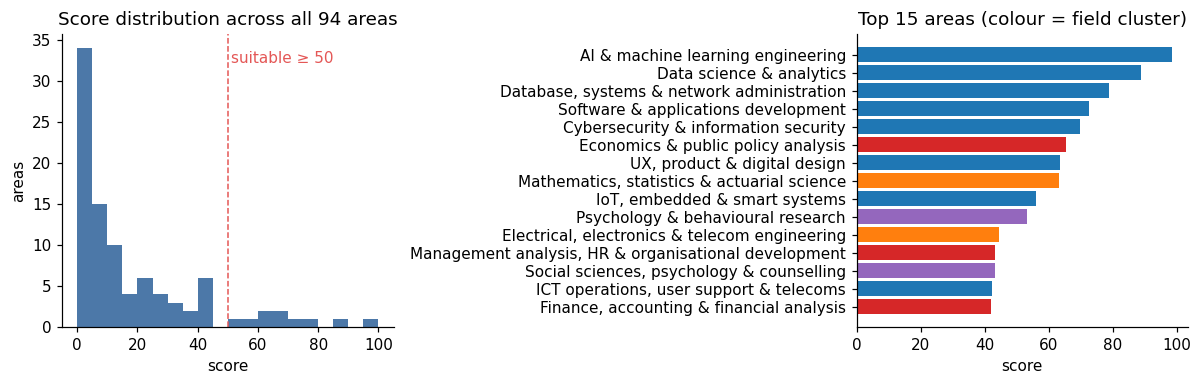

In [11]:
gate = scoring.sanity_gate(scores)
print({k: v for k, v in gate.items() if k not in ("top10_clusters",)})
print("top-10 by cluster:", gate["top10_clusters"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(scores.score, bins=np.arange(0, 101, 5), color="#4C78A8")
ax[0].axvline(scoring.MODERATE, color="#E45756", ls="--", lw=1); ax[0].text(51, ax[0].get_ylim()[1]*0.9, "suitable ≥ 50", color="#E45756")
ax[0].set_title("Score distribution across all 94 areas"); ax[0].set_xlabel("score"); ax[0].set_ylabel("areas")
top = scores.head(15).iloc[::-1]
pal = {c: col for c, col in zip(catalogue.CLUSTERS, plt.cm.tab10.colors)}
ax[1].barh(top.name, top.score, color=[pal[c] for c in top.cluster])
ax[1].set_title("Top 15 areas (colour = field cluster)"); ax[1].set_xlabel("score")
plt.tight_layout(); plt.show()

## 7. Dry run 1 failed the gate, and why

The first version simply **added** four weighted components (CV 35, personality 25, interests 25,
readiness 15; interests dropped and weights renormalised because none were given). We kept it as a
function so the failure is reproducible:

In [12]:
def score_v1_additive(sc, p, w=dict(cv=0.35, personality=0.25, readiness=0.15)):
    cv, _ = sc._concept_component({k: v["strength"] for k, v in p.cv_concepts.items()})
    pe, pe_w, _ = sc._personality_component(p.personality)
    rd = sc._readiness_component(p)
    tot = sum(w.values())
    return 100 * (w["cv"] * cv + w["personality"] * pe + w["readiness"] * rd) / tot

v1 = pd.Series(score_v1_additive(sc, prof), index=sc.cat.name).sort_values(ascending=False)
v1_share = (v1 >= 50).mean()
print(f"v1 additive: {v1_share:.0%} of areas 'suitable'  (limit 25%)  -> gate {'PASSED' if v1_share <= .25 else 'FAILED'}")
print("\nv1 put these clinical areas above 'suitable' on weak CV evidence (0.22-0.35 of the best area's):")
cvv = pd.Series(sc._concept_component({k: v['strength'] for k, v in prof.cv_concepts.items()})[0], index=sc.cat.name)
pd.DataFrame({"v1 score": v1, "cv evidence": cvv}).loc[["Medicine", "Nursing & midwifery", "Paramedic & emergency care"]].round(2)

v1 additive: 50% of areas 'suitable'  (limit 25%)  -> gate FAILED

v1 put these clinical areas above 'suitable' on weak CV evidence (0.22-0.35 of the best area's):


,v1 score,cv evidence
name,,
Medicine,66.87,0.35
Nursing & midwifery,64.21,0.30
Paramedic & emergency care,61.24,0.22


**Diagnosis.** Personality fit and readiness are *near-constant* across the 50+ degree-level areas, so adding
them gives every area a ~45-point floor regardless of CV evidence. Personality describes **how** someone likes
to work, not **which field**; it must not be able to lift an area the CV never mentions.

**Fix (D4):** combine **multiplicatively**: relevance (CV and interests) is the base; work-style can only
scale it between `1 - influence` and 1; readiness is a multiplier. The gate then passed (§6.2).

**A second flaw found while testing the passion case (D5).** Our first replacement used a weighted *average*
of CV and interests. Adding a single hobby then capped every CV-based area at ~58, because the average dilutes
the CV with a zero. Interests should *add*, never penalise, so relevance became the probabilistic OR in §6.1.
Test `test_stated_passion_creates_wildcard_without_cv_evidence` now asserts "a passion never lowers a
CV-evidenced area".

In [13]:
# the dilution flaw, shown on the AI & ML area with a music passion
cv_ai = float(scores.set_index("name").loc["AI & machine learning engineering", "cv"])
print(f"cv = {cv_ai:.2f}, interest = 0")
print(f"  weighted-average relevance (flawed): {(0.35*cv_ai + 0.25*0)/(0.35+0.25):.2f}")
print(f"  OR relevance (current)             : {1-(1-cv_ai)*(1-0.6*0):.2f}")

cv = 1.00, interest = 0
  weighted-average relevance (flawed): 0.58
  OR relevance (current)             : 1.00


## 8. Reading the result

### 8.1 Evidence behind the top areas

The engine never shows a rank without a reason. For the top five:

In [14]:
for _, r in scores.head(5).iterrows():
    print(f"#{r['rank']}  {r['name']}  ({r.score:.0f})   [{r.cluster}]")
    print("   CV evidence :", r.why_cv)
    print("   Work-style  :", r.why_personality)
    print("   Level       :", r.why_readiness)
    if r.missing: print("   Not on CV   :", r.missing)
    print("   Example roles:", ", ".join(r.examples[:4]))
    print()

#1  AI & machine learning engineering  (99)   [Technology & Data]
   CV evidence : Machine learning & AI (machine learning, ai, nlp); Systems & requirements analysis (requirement, specification, system testing); Data analytics & visualisation (data analy, data mining, dashboard)
   Work-style  : ideas and patterns work fits (Intuition 70%); planned and structured work fits (Judging 65%)
   Level       : your education fits: skill levels 3-4 (degree-level)
   Example roles: Business analyst (IT), Computer scientist, Information systems analyst, Systems consultant

#2  Data science & analytics  (89)   [Technology & Data]
   CV evidence : Data analytics & visualisation (data analy, data mining, dashboard); Databases & data engineering (mysql, mongodb, oracle); Statistics & quantitative modelling (statistic, regression, forecast)
   Work-style  : ideas and patterns work fits (Intuition 70%); planned and structured work fits (Judging 65%)
   Level       : your education fits: skill levels 3

### 8.2 Spot-check the bottom and the "unexpected"

The consultant's worry is false *negatives* ("I'm passionate about music, it's not on my CV"). We cannot
fully test that without the participant, but we can list areas that deserve a human look: strong CV evidence
but a low final score, and well-known fields that scored near zero.

In [15]:
s = scores.set_index("name")
print("Areas with notable CV evidence (cv >= 0.30) but final score < 30, and why:")
display(s[(s.cv >= 0.30) & (s.score < 30)][["cv", "modifier", "readiness", "score", "why_readiness"]].round(2))
print("\nLowest 8 areas:")
display(scores[["name", "cluster", "score"]].tail(8).round(1))

Areas with notable CV evidence (cv >= 0.30) but final score < 30, and why:


,cv,modifier,readiness,score,why_readiness
name,,,,,
Nursing & midwifery,0.30,0.98,1.00,29.7,your education fits: skill levels 3-4 (degree-level)
"Training, learning & development",0.30,0.96,1.00,29.3,your education fits: skill levels 3-4 (degree-level)
ICT service management,0.53,0.96,0.45,22.9,your education fits: skill levels 3-4 (degree-level); management also needs ...
"Sales, marketing & R&D management",0.46,0.94,0.45,19.5,your education fits: skill levels 3-4 (degree-level); management also needs ...
Business services & administration management,0.35,0.93,0.45,15.0,your education fits: skill levels 3-4 (degree-level); management also needs ...



Lowest 8 areas:


,name,cluster,score
86,"Protective services (police, fire, security)","Education, Social & Public Service",1.0
87,Food processing & baking trades,"Production, Trades, Transport & Operations",1.0
88,"Hairdressing, beauty & grooming","Hospitality, Retail & Personal Services",0.9
89,Banking & payment services clerks,"Business, Finance & Management",0.9
90,"Street services, waste collection & other elementary work","Hospitality, Retail & Personal Services",0.7
91,"Subsistence farming, fishing & agricultural labour","Agriculture, Forestry & Fisheries",0.6
92,"Metalwork, welding & fabrication","Production, Trades, Transport & Operations",0.6
93,Cleaning services,"Hospitality, Retail & Personal Services",0.3


Of the five rows above, **three are management areas** (ICT service, sales/R&D, business services management):
the CV evidence is real but they typically need track record she does not yet have (readiness ×0.45), which is
the readiness factor behaving as designed. The other two (**Nursing**, **Training**) simply sit just above the
0.30 evidence threshold we chose for this table, so they are weak adjacencies, not suppressed strengths.

**Items to verify with the participant (not conclusions):**

* **Cybersecurity & information security** ranks in the top 5 although the CV never mentions security. It
  inherits from *networks, databases, cloud*. Likely a false positive, a good first test of "adjacent but not
  evidenced" in the validation form.
* **Management analysis, HR & organisational development** ranks only about 12th although the CV has genuine
  workforce/culture research and stakeholder reporting. The ISCO text for that area is less
  technology-flavoured than the lens areas, so it scores lower on the data vocabulary. A possible false negative.
* **Seven of the top ten are Technology & Data.** That matches the CV, but is exactly the "one-field" result the
  consultant wants widened. §10 shows how narrowing and the diversity step respond.

### 8.3 Hidden passions (R7, the music example)

Thilakshana's profile has no stated interests, so the passion route was not exercised. We can demonstrate
the mechanism with an *illustrative* intake, clearly not a real answer from her:

In [16]:
def top_names(p, k=12):
    return PL.run(p)["scores"][["rank", "name", "score"]].head(k)

base = PL.run(PL.sample_profile())["scores"].set_index("name")
demo = PL.run(PL.sample_profile(interest_ids=["music_arts", "entrepreneurship"]))["scores"].set_index("name")
cmp = pd.DataFrame({
    "rank (CV + PersonaMap)": base["rank"], "score": base.score,
    "rank (+ illustrative passions)": demo["rank"], "score ": demo.score,
}).loc[["Music performance & production", "Creative & performing arts", "Executive leadership & general management",
        "AI & machine learning engineering", "Data science & analytics", "Software & applications development"]]
cmp["cv evidence"] = base.cv.round(2)
cmp

,rank (CV + PersonaMap),score,rank (+ illustrative passions),score,cv evidence
name,,,,,
Music performance & production,53,7.3,12,54.6,0.08
Creative & performing arts,67,3.8,20,43.9,0.04
Executive leadership & general management,52,7.8,44,17.0,0.19
AI & machine learning engineering,1,98.6,1,98.6,1.00
Data science & analytics,2,88.9,2,89.4,0.97
Software & applications development,4,72.7,4,77.5,0.75


Music performance & production moves from rank 53 to 12, and Creative & performing arts from 67 to 20,
**without any CV evidence** (CV evidence 0.08 and 0.04). CV-evidenced areas do not lose score (some gain a
little through shared vocabulary). A stated passion alone is intentionally capped (`interest_strength` = 0.6):
enough to land in the "worth exploring" list and be flagged, not enough to outrank strong evidence.
Entrepreneurship moves Executive leadership only from 52nd to 44th: ISCO classifies by job content, not by
the mode of working (D2), and that area is also held down by the experience-based readiness factor.

## 9. What actually drives the ranking?

Before showing anyone a personality-flavoured result we should know how much each part contributes. This is
an **ablation**: rebuild the ranking with parts removed and compare the Top 10.

In [17]:
def top10(vec): return list(pd.Series(vec, index=sc.cat.name).sort_values(ascending=False).head(10).index)
cv, _ = sc._concept_component({k: v["strength"] for k, v in prof.cv_concepts.items()})
rd = sc._readiness_component(prof)
pe_raw, _, _ = sc._personality_component(prof.personality)
pe = (pe_raw - pe_raw.min()) / (pe_raw.max() - pe_raw.min())
variants = {
    "CV evidence only":            100 * cv,
    "+ readiness":                 100 * cv * rd,
    "+ work-style (full model)":   100 * cv * rd * ((1 - .35) + .35 * pe),
}
full = set(top10(variants["+ work-style (full model)"]))
rows = []
for k, v in variants.items():
    t = set(top10(v))
    rows.append((k, len(t & full), sorted(full - t), sorted(t - full)))
pd.DataFrame(rows, columns=["variant", "overlap with full Top 10 (of 10)", "in full model, not here", "here, not in full model"])

,variant,overlap with full Top 10 (of 10),"in full model, not here","here, not in full model"
0,CV evidence only,10,[],[]
1,+ readiness,10,[],[]
2,+ work-style (full model),10,[],[]


In [18]:
# sensitivity to the work-style influence parameter (0 = personality ignored): position of each area
pos = {}
for infl in [0.0, 0.2, 0.35, 0.5, 0.6]:
    sc.weights = dict(interest_strength=0.6, personality_influence=infl)
    pos[infl] = list(sc.score(prof).name)
sc.weights = dict(scoring.DEFAULT_WEIGHTS)
order0 = pos[0.0][:12]
tab = pd.DataFrame({f"influence {k}": [pos[k].index(n) + 1 for n in order0] for k in pos}, index=order0)
tab.index.name = "area (ordered as when personality is ignored)"
same_members = all(set(pos[k][:10]) == set(pos[0.0][:10]) for k in pos)
print("Same ten areas in the Top 10 at every influence level:", same_members)
tab

Same ten areas in the Top 10 at every influence level: True


,influence 0.0,influence 0.2,influence 0.35,influence 0.5,influence 0.6
area (ordered as when personality is ignored),,,,,
AI & machine learning engineering,1,1,1,1,1
Data science & analytics,2,2,2,2,2
"Database, systems & network administration",3,3,3,3,3
Software & applications development,4,4,4,4,4
Economics & public policy analysis,5,6,6,7,7
Cybersecurity & information security,6,5,5,5,5
"Mathematics, statistics & actuarial science",7,7,8,8,8
"UX, product & digital design",8,8,7,6,6
Psychology & behavioural research,9,10,10,10,10


**Reading this honestly.** For this profile, personality **never changes who is in the Top 10**; at the
extremes it only swaps neighbouring places between ranks 5 and 10 (e.g. UX moves up two places, Economics down
two) and pushes one area (Social sciences & counselling) from 11th to outside the top 12. That is partly by
design (§7: work-style cannot create relevance) and partly because the top ten are all ideas-and-analysis
work, so their work-style fit is similar. It also means that **for a person with a clear CV, the Top 10 is
essentially determined by the CV**, so the interests intake (R7) is the main lever for widening the result.
We should tell the supervisor this plainly rather than present personality as the driver.

The corollary matters for the research design: with only one profile we cannot tell whether work-style adds
real value. The testers' accuracy comments on the "Work-style" reasons (§11) are the evidence we need.

## 10. Narrowing to a Top 10 with the participant's reactions

The participant is never asked to rate the full list. The flow (`careerx.narrowing`, also in the app, tab 4):

| Round | What the participant does | Items |
|---|---|---|
| 0 | Nothing. The engine builds a shortlist: top 10 "highly suitable" + next 10 "moderately suitable" (+ up to 3 passion wildcards) | ~20 |
| 1 | Picks the **fields** that draw them (or none) | 1 tap |
| 2 | **Like / maybe / no** per remaining area, with a short *why / why not* | ≤ ~20 taps |
| 3 | 2-3 forced choices ("which first?") around the cut-off | 3 taps |

The final score blends the model score (60%) with the participant's reaction (40%), applies duel bonuses,
removes anything they said "no" to, and picks the Top 10 with a **diversity** penalty so five near-identical
data areas do not crowd out everything else.

In [19]:
sl = narrowing.shortlist(scores)
print("shortlist size:", len(sl))
sl[["list", "name", "cluster", "score"]].round(1)

shortlist size: 20


,list,name,cluster,score
0,Highly suitable,AI & machine learning engineering,Technology & Data,98.6
1,Highly suitable,Data science & analytics,Technology & Data,88.9
2,Highly suitable,"Database, systems & network administration",Technology & Data,78.7
3,Highly suitable,Software & applications development,Technology & Data,72.7
4,Highly suitable,Cybersecurity & information security,Technology & Data,69.7
5,Highly suitable,Economics & public policy analysis,"Business, Finance & Management",65.3
6,Highly suitable,"UX, product & digital design",Technology & Data,63.4
7,Highly suitable,"Mathematics, statistics & actuarial science","Science, Engineering & Built Environment",63.1
8,Highly suitable,"IoT, embedded & smart systems",Technology & Data,56.1
9,Highly suitable,Psychology & behavioural research,"Education, Social & Public Service",53.2


### 10.1 A *simulated* participant

We have no real reactions yet, so to show the mechanics we script an **imaginary** participant who is drawn to
people-and-meaning-flavoured analytics and dislikes security/infrastructure. **This is a demonstration of the
mechanism only; it says nothing about Thilakshana's real preferences.**

In [20]:
likes = ["Psychology & behavioural research", "Data science & analytics", "UX, product & digital design",
         "Economics & public policy analysis", "Management analysis, HR & organisational development",
         "Social sciences, psychology & counselling"]
nos = ["Cybersecurity & information security", "Database, systems & network administration",
       "Electrical, electronics & telecom engineering"]
by_name = dict(zip(sl.name, sl.area_id))
ratings = {by_name[n]: dict(pref="like", reason="draws on people and meaning") for n in likes if n in by_name}
ratings.update({by_name[n]: dict(pref="no", reason="too far from people") for n in nos if n in by_name})

d2 = narrowing.apply_ratings(sl, ratings)
sim = narrowing.area_similarity(sc.X, list(d2.area_id), list(cat.area_id))
groups = narrowing.duel_groups(d2)
print("tie-break groups:", [[dict(zip(d2.area_id, d2.name))[a] for a in g] for g in groups])
picks = [g[0] for g in groups]            # the simulated participant always takes the first option
top_sim = narrowing.final_top(d2, duel_picks=picks, sim=sim, diversity=0.25)
top_sim[["final_rank", "name", "cluster", "score", "pref", "reason"]].round(1)

tie-break groups: [['Management analysis, HR & organisational development', 'Social sciences, psychology & counselling', 'Software & applications development'], ['Mathematics, statistics & actuarial science', 'IoT, embedded & smart systems', 'ICT operations, user support & telecoms'], ['Finance, accounting & financial analysis', 'Life sciences, biology & laboratory science', 'Architecture, planning, surveying & design']]


,final_rank,name,cluster,score,pref,reason
0,1,Data science & analytics,Technology & Data,88.9,like,draws on people and meaning
1,2,Economics & public policy analysis,"Business, Finance & Management",65.3,like,draws on people and meaning
2,3,AI & machine learning engineering,Technology & Data,98.6,maybe,
3,4,"UX, product & digital design",Technology & Data,63.4,like,draws on people and meaning
4,5,"Management analysis, HR & organisational development","Business, Finance & Management",43.3,like,draws on people and meaning
5,6,Psychology & behavioural research,"Education, Social & Public Service",53.2,like,draws on people and meaning
6,7,"Social sciences, psychology & counselling","Education, Social & Public Service",43.3,like,draws on people and meaning
7,8,"Mathematics, statistics & actuarial science","Science, Engineering & Built Environment",63.1,maybe,
8,9,Software & applications development,Technology & Data,72.7,maybe,
9,10,"IoT, embedded & smart systems",Technology & Data,56.1,maybe,


### 10.2 What the diversity step really does (measured, model-only Top 10)

Several of the top areas are near-duplicates because they share ISCO unit groups. Cosine similarity between
areas makes this visible:

In [21]:
ids = list(sl.area_id[:10]); nm = dict(zip(cat.area_id, cat.name))
S = narrowing.area_similarity(sc.X, ids, list(cat.area_id))
pairs = [(nm[a], nm[b], round(float(S.loc[a, b]), 2)) for i, a in enumerate(ids) for b in ids[i + 1:]]
display(pd.DataFrame(pairs, columns=["area A", "area B", "text similarity"]).sort_values("text similarity", ascending=False).head(5))

d0m = narrowing.apply_ratings(sl, {})
rows, base_set = [], None
for dv in [0.0, 0.25, 0.5, 0.75]:
    t = narrowing.final_top(d0m, sim=narrowing.area_similarity(sc.X, list(d0m.area_id), list(cat.area_id)), diversity=dv)
    names = set(t.name)
    base_set = base_set or names
    rows.append((dv, t.cluster.nunique(), int((t.cluster == "Technology & Data").sum()),
                 ", ".join(sorted(names - base_set)) or "-", ", ".join(sorted(base_set - names)) or "-"))
pd.DataFrame(rows, columns=["diversity", "clusters in Top 10", "of which Technology", "enters", "leaves"])

,area A,area B,text similarity
18,"Database, systems & network administration",Cybersecurity & information security,0.92
26,Software & applications development,"UX, product & digital design",0.79
0,AI & machine learning engineering,Data science & analytics,0.71
6,AI & machine learning engineering,"Mathematics, statistics & actuarial science",0.71
14,Data science & analytics,"Mathematics, statistics & actuarial science",0.67


,diversity,clusters in Top 10,of which Technology,enters,leaves
0,0.00,4,7,-,-
1,0.25,4,7,-,-
2,0.50,4,5,"Finance, accounting & financial analysis, Life sciences, biology & laborator...","Cybersecurity & information security, UX, product & digital design"
3,0.75,5,5,"Finance, accounting & financial analysis, Life sciences, biology & laborator...","Cybersecurity & information security, Mathematics, statistics & actuarial sc..."


**Honest reading.** At the default (0.25) the diversity step changes nothing for this profile, and the
simulated reactions above give an identical Top 10 with and without it. It only starts acting at about 0.5,
where the near-duplicates (Cybersecurity ≈ Database administration, similarity 0.92; UX ≈ Software
development, 0.79) are replaced by areas with **weaker CV evidence** (Finance, Life sciences). So there is a
genuine trade-off between *breadth* (the consultant's "spectrum of areas") and *evidence*, and the right
setting is a product decision to make with him, not something to hide in a default. The app exposes the slider.

## 11. Validation design for the internal testers (R3, R6)

The consultant's research protocol, implemented as a form (app tab 6, or the CSV below):

1. Each tester gets the **numbered full map** (all 94 areas, ordered by score and grouped by field).
2. Per line they give **accuracy 1-5**: *"how accurate is this match for you?"* A low score judged correct
   counts as accurate; a low score judged *wrong* is a false negative, the most valuable row.
3. A **comment is required unless the line is rated 5 (highly accurate)**: "why isn't it highly accurate?".
4. To keep the effort sane, a whole field can be bulk-confirmed as accurate; realistically 30-40 lines need
   real thought, but the full list is always available.
5. We track: mean accuracy, % rated 4-5 (target ≈ 90%), accuracy **by score band**, and the lists of
   false positives and false negatives. Three refinement rounds.

In [22]:
fb = feedback.feedback_template(scores)
print("columns:", list(fb.columns))
print("rows:", len(fb), "| scale:", feedback.ACCURACY_SCALE)
fb.head(12)

columns: ['no', 'area_id', 'career_area', 'cluster', 'match_score', 'accuracy', 'comment']
rows: 94 | scale: {5: '5 - Highly accurate', 4: '4 - Accurate', 3: '3 - Partly accurate', 2: '2 - Inaccurate', 1: '1 - Very inaccurate'}


,no,area_id,career_area,cluster,match_score,accuracy,comment
0,1,A087,AI & machine learning engineering,Technology & Data,98.6,<NA>,
1,2,A086,Data science & analytics,Technology & Data,88.9,<NA>,
2,3,A044,"Database, systems & network administration",Technology & Data,78.7,<NA>,
3,4,A043,Software & applications development,Technology & Data,72.7,<NA>,
4,5,A090,Cybersecurity & information security,Technology & Data,69.7,<NA>,
5,6,A092,Economics & public policy analysis,"Business, Finance & Management",65.3,<NA>,
6,7,A088,"UX, product & digital design",Technology & Data,63.4,<NA>,
7,8,A013,"Mathematics, statistics & actuarial science","Science, Engineering & Built Environment",63.1,<NA>,
8,9,A089,"IoT, embedded & smart systems",Technology & Data,56.1,<NA>,
9,10,A091,Psychology & behavioural research,"Education, Social & Public Service",53.2,<NA>,


**What each failure mode tells us to fix** (the "why did it match that?" loop in the transcript):

| Pattern in the feedback | Likely cause | Where we fix it |
|---|---|---|
| High score, low accuracy, comment mentions *context* ("that was a project for a clinic") | Domain words in a CV are not a career signal | Lexicon triggers (`lexicon.py`) |
| High score in an area with no CV evidence (e.g. cybersecurity) | Adjacency in ISCO vocabulary | Concept vocabularies / affinity exponent |
| Low score, low accuracy, comment says "I love this" | Hidden passion | Interests intake wording, `interest_strength` |
| Whole field mis-scored | Catalogue merge or lens text | `catalogue.py` |
| Everyone rates the work-style reasons as irrelevant | Personality axes poorly measured from ISCO text | Trait cues in `lexicon.TRAIT_CUES` |

## 12. Outputs written to disk

In [23]:
out = ROOT / "outputs"; proc = ROOT / "data" / "processed"
out.mkdir(exist_ok=True); proc.mkdir(exist_ok=True)

cat.drop(columns=["text", "examples"]).to_csv(proc / "career_area_catalogue.csv", index=False)
scores.drop(columns=["examples"]).to_csv(out / "thilakshana_full_map.csv", index=False)
feedback.feedback_template(scores).to_csv(out / "thilakshana_feedback_form.csv", index=False)
PL.profile_to_json(prof, ROOT / "data" / "profiles" / "thilakshana.json")

# Model-only Top 10: what the engine gives BEFORE the participant has reacted to anything
d0 = narrowing.apply_ratings(sl, {})
sim0 = narrowing.area_similarity(sc.X, list(d0.area_id), list(cat.area_id))
top_model = narrowing.final_top(d0, sim=sim0, diversity=0.25)
(out / "thilakshana_top10_model_only.md").write_text(report.build_markdown(prof, top_model, scores, gate), encoding="utf-8")
print("written:", [p.name for p in sorted(out.iterdir())] + ["data/processed/career_area_catalogue.csv"])
top_model[["final_rank", "name", "cluster", "score"]].round(1)

written: ['thilakshana_feedback_form.csv', 'thilakshana_full_map.csv', 'thilakshana_top10_model_only.md', 'data/processed/career_area_catalogue.csv']


,final_rank,name,cluster,score
0,1,AI & machine learning engineering,Technology & Data,98.6
1,2,Data science & analytics,Technology & Data,88.9
2,3,"Database, systems & network administration",Technology & Data,78.7
3,4,Software & applications development,Technology & Data,72.7
4,5,Cybersecurity & information security,Technology & Data,69.7
5,6,Economics & public policy analysis,"Business, Finance & Management",65.3
6,7,"UX, product & digital design",Technology & Data,63.4
7,8,"Mathematics, statistics & actuarial science","Science, Engineering & Built Environment",63.1
8,9,"IoT, embedded & smart systems",Technology & Data,56.1
9,10,Psychology & behavioural research,"Education, Social & Public Service",53.2


The table above is the **Phase 1 output for Thilakshana as it stands today**: the model-only Top 10,
before she has reacted to anything and before she has given any interests. It becomes her real Top 10 only
after the §10 flow with her own answers.

## 13. Findings, limitations and next steps

### What we can say
* The **method works end to end** on real documents: parse → catalogue of 94 areas → full scoring → quality
  gate → shortlist → narrowing → Top 10, with traceable evidence for every number.
* The **quality gate caught a real flaw** in our first formula (§7), which is evidence that the check is
  meaningful and not decorative.
* For this participant the data/AI core is unambiguous (CV-driven); personality only **swaps neighbouring
  ranks** and never changed Top-10 membership (§9), so on this profile its value is unproven.
* A stated passion can surface an area the CV never mentions (§8.3), the mechanism the consultant's "music"
  example needs. It has been shown with an *illustrative* intake only.

### What we cannot say yet
* That any of this is *accurate*. One participant, no human feedback. The 90% target is untested.
* That the lexicon generalises: it was adjusted after looking at this CV (D3).
* Anything about her interests (the intake has not been collected). The leadership-style section of her
  PersonaMap report exists (it says she would involve and develop people, and sets pace least naturally) but
  the engine does not use it yet, and no separate leadership questionnaire output has been provided.

### Known limitations
| # | Limitation | Planned handling |
|---|---|---|
| L1 | ISCO-08 predates data science, AI, UX etc.; lens areas use a short supplement text | Review lens text with the consultant; consider O\*NET / ISCO-26 enrichment |
| L2 | The concept lexicon is hand-written and English-only | Refine through the 3 validation rounds; Sinhala/Tamil CV terms later |
| L3 | Context vs. role confusion (a project *for* a clinic is not a healthcare career signal) | Weight work-experience mentions above project mentions |
| L4 | Personality is measured against ISCO *text*, a rough proxy for work style | Validate; replace with curated trait ratings if needed |
| L5 | No Sri Lanka-specific occupation list or labour-market data | Local adaptation (R2) |
| L6 | "Entrepreneurship"/self-employment is not an ISCO concept | Handle as an interest/mode flag, not an area |

### Decision log
| ID | Decision | Alternative rejected | Reason |
|---|---|---|---|
| D1 | Score all areas, soft shortlist, narrow by reaction | Hard sector → sub-group → job funnel | Major groups encode skill level, not field; early errors unrecoverable |
| D2 | Catalogue of **areas** merged across levels + 9 lens areas | Use ISCO minor groups as-is | "Area, not designation, not level" (R1) |
| D3 | Rule-based, transparent scorer (lexicon + TF-IDF) | LLM judge now | Reproducible, explainable, zero cost; LLM can sit behind the same interface later |
| D4 | Multiplicative combination | Additive weighted sum | Additive failed the selectivity gate (§7) |
| D5 | Interests combine by OR | Weighted average with CV | Averaging made one hobby lower every CV area |
| D6 | Balanced personality dimension gets zero weight | Use 50% as a data point | The report itself refuses to infer a pattern there |
| D7 | PersonaMap never leaves the participant's own report | Pass to employers in Phase 2 | Report is marked not for selection decisions |
| D8 | Optional Top-10 diversity penalty (default 0.25, a no-op for this profile; §10.2) | Pure score order | Allow trading evidence for breadth ("a spectrum of areas"); setting to be agreed with the consultant |

### Suggested next steps
1. Collect the **interests intake** for Thilakshana and rerun. Agree with the consultant how the report's
   leadership-style section (and any separate leadership questionnaire) should feed the match.
2. Run the other four testers' CV + PersonaMap through the **same** engine, unchanged, and compare the
   score distributions (the gate must hold for all five).
3. Run **validation round 1** with the feedback form; fix by the table in §11; repeat for 3 rounds.
4. Only then design **Phase 2** (market vacancies, employer outreach, study vs. professional path), with a
   consent and compliance review for contacting employers and for how personality data is used.

### To reproduce
```
python tests/test_pipeline.py                 # 10 checks from the plan
python notebooks/build_notebook.py            # regenerate and execute this notebook
streamlit run app/streamlit_app.py            # the test app
```